In [ ]:
!pip install memory_profiler

import numpy as np
import numba as nb
import matplotlib.pyplot as plt
import psutil
import os
from memory_profiler import memory_usage

# Задания.

1. Изучите реализацию многомерных массивов numpy.ndarray и работу с ними в numba.
Посмотрите ноутбук [FastPython.](../FastPython.ipynb)

2. Реализуйте произведение матриц $A\in Mat(N\times K)$, $B\in Mat(K\times M)$ согласно определению
$$
C_{n,m}=\sum_{k=1}^K A_{n,k}B_{k,m}.
$$
Сравните быстродействие реализаций на основе numpy.sum, с помощью numba и стандартный метод numpy.dot.
Насколько полно используется процессор?
Сколько используется памяти?

3. Составьте модель использования вычислительных ресурсов функцией на основе numba.jit из предыдущего пункта.
Размеры матриц должны быть параметрами модели.
Проведите вычислительные эксперименты, чтобы подобрать параметры модели.
Экстраполируйте результат на большие матрицы, сделайте экспериментальную проверку.

4. В простейшем алгоритме произведения матриц используются три цикла: перебирающие элементы $n$ и $m$  матрицы $C$
и суммирующие по $k$.
Сравните время перемножения матриц в зависимости от порядка циклов.
Оцените объем кэшей разных уровней, проводя эксперименты для матриц разного размера.

5. Обновите функцию для перемножения матриц, используя несколько потоков с помощью numba.prange.
Обновите модель использования вычислительных ресурсов, принимая во внимание число потоков.
Оцените параметры модели из эксперимента.
Какое [параллельное ускорение](https://en.wikipedia.org/wiki/Amdahl%27s_law) вы получили?

6. Сможете ли вы реализовать реализовать на С более быстрый вариант перемножения матриц, чем на numba?

7. Реализуйте быстрое произведение матриц, например, используйте [алгоритм Штрассена](https://en.wikipedia.org/wiki/Strassen_algorithm).
Оцените, на матрицах какого размера быстрое произведение матриц быстрее, чем стандартная реализация.
Какой из методов дает меньшую погрешность вычислений?


In [ ]:
# Задание 2


pid=os.getpid()
py_pros=psutil.Process(pid)



#Реализуем самый обычный алгоритм - влоб:

def my_dot(A,B):
    C=[]
    for n in range(len(A)):
        Cn=[]
        for m in range(len(B[0])):
            Cnm=0
            for k in range(len(B)):
                Cnm+=A[n][k]*B[k][m]
            Cn.append(Cnm)
        C.append(Cn)
    return C


#Реализуем аналогичный алгоритм, но на основе numpy.sum

def np_my_dot(A,B):
    C=np.empty([A.shape[0],B.shape[1]])
    for n in range(A.shape[0]):
        for m in range(B.shape[1]):
            C[n, m] = np.sum( A[n,:]*B[:,m])
    return C

#Оптимизируем алгоритм с помощью numba

@nb.njit(nb.float64[:,:](nb.float64[:,:],nb.float64[:,:]))
def nb_my_dot(A,B):
    C=np.empty((A.shape[0],B.shape[1]))
    for n in range(A.shape[0]):
        for m in range(B.shape[1]):
            C[n, m] = np.sum( A[n,:]*B[:,m])
    return C


A = np.random.rand(100, 120)
B = np.random.rand(120, 100)

%load_ext memory_profiler

print('Default algorythm')
psutil.cpu_percent()
%timeit my_dot(A,B)
print('CPU usage:', psutil.cpu_percent(), '%')
%memit my_dot(A,B)

print('Default algorythm (using numpy functions)')
psutil.cpu_percent()
%timeit np_my_dot(A,B)
print('CPU usage:', psutil.cpu_percent(), '%')
%memit np_my_dot(A,B)

print('Default algorythm with Numba')
psutil.cpu_percent()
%timeit nb_my_dot(A,B)
print('CPU usage:', psutil.cpu_percent(), '%')
%memit nb_my_dot(A,B)

print('Standart Numpy dot function')
psutil.cpu_percent()
%timeit np.dot(A,B)
print('CPU usage:', psutil.cpu_percent(), '%')
%memit np.dot(A,B)

Default algorythm
993 ms ± 257 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
CPU usage: 72.8 %
peak memory: 229.02 MiB, increment: 0.14 MiB
Default algorythm (using numpy functions)
54.7 ms ± 9.78 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
CPU usage: 59.2 %
peak memory: 229.02 MiB, increment: 0.00 MiB
Default algorythm with Numba
4.55 ms ± 745 µs per loop (mean ± std. dev. of 7 runs, 100 loops each)
CPU usage: 71.2 %
peak memory: 229.02 MiB, increment: 0.00 MiB
Standart Numpy dot function
147 µs ± 58 µs per loop (mean ± std. dev. of 7 runs, 10000 loops each)
CPU usage: 100.0 %
peak memory: 229.45 MiB, increment: 0.00 MiB


### Задание 3

Рассмотрим квадратные матрицы и построим графики зависимости времени подсчета от размера матрицы, а также сделаем экстарполяцию


100%|██████████| 200/200 [00:31<00:00,  6.26it/s]


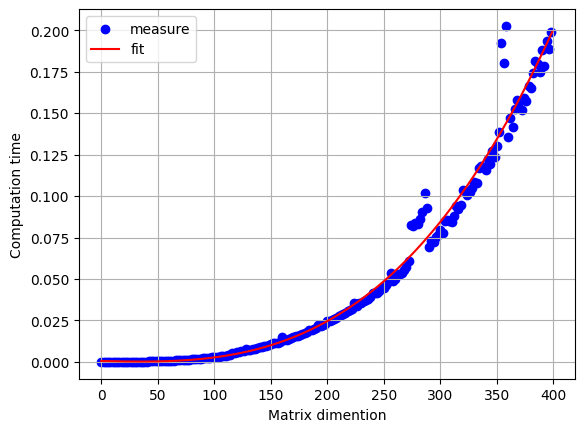

In [ ]:
from timeit import default_timer as timer
from tqdm import tqdm
from scipy.optimize import curve_fit

def func(x, a, b, c,d):
    return a * x**3+b*x**2+c*x+d

def measure_time(N,dot, repeat=3):
    Time=[]
    for n in tqdm(N):
        compute_time_repeat=[]
        for _ in range(repeat):
            A = np.random.rand(n, n)
            B = np.random.rand(n, n)
            current_time=timer()
            dot(A,B)
            compute_time=timer()-current_time
            compute_time_repeat.append(compute_time)
        Time.append(min(compute_time_repeat))
    return Time
N_max=400
N=[i for i in range(0,N_max,2)]
N_cont=np.arange(0,N_max,1)
Measure=measure_time(N, nb_my_dot, repeat=3)
fit ,cov = curve_fit(func, N, Measure)
plt.scatter(N, Measure, c='blue', label='measure')
plt.plot(N_cont, func(N_cont,*fit), c='red', label='fit')
plt.grid()
plt.legend()
plt.xlabel('Matrix dimention')
plt.ylabel('Computation time')
plt.show()


Задание 4. В простейшем алгоритме произведения матриц используются три цикла: перебирающие элементы $n$ и $m$  матрицы $C$
и суммирующие по $k$.
Сравните время перемножения матриц в зависимости от порядка циклов.
Оцените объем кэшей разных уровней, проводя эксперименты для матриц разного размера.


In [ ]:

@nb.njit(nb.float64[:,:](nb.float64[:,:],nb.float64[:,:]))
def dot_nmk(A,B):
    C = np.empty((A.shape[0], B.shape[1]))
    for n in range(A.shape[0]):
        for m in range(B.shape[1]):
          Cnm = 0
          for k in range(B.shape[0]):
            Cnm +=  A[n,k] * B[k, m]
          C[n, m] = Cnm
    return C


@nb.njit(nb.float64[:,:](nb.float64[:,:],nb.float64[:,:]))
def dot_mnk(A,B):
    C = np.empty((A.shape[0], B.shape[1]))
    for m in range(B.shape[1]):
        for n in range(A.shape[0]):
          Cnm = 0
          for k in range(B.shape[0]):
            Cnm +=  A[n,k] * B[k, m]
          C[n, m] = Cnm
    return C


@nb.njit(nb.float64[:,:](nb.float64[:,:],nb.float64[:,:]))
def dot_nkm(A, B):
    C = np.empty((A.shape[0], B.shape[1]))
    for n in range(A.shape[0]):
        for k in range(B.shape[0]):
            for m in range(B.shape[1]):
                C[n, m] +=  A[n,k] * B[k, m]
    return C

@nb.njit(nb.float64[:,:](nb.float64[:,:],nb.float64[:,:]))
def dot_mkn(A, B):
    C = np.empty((A.shape[0], B.shape[1]))
    for m in range(B.shape[1]):
        for k in range(B.shape[0]):
            for n in range(A.shape[0]):
                C[n, m] +=  A[n,k] * B[k, m]
    return C

@nb.njit(nb.float64[:,:](nb.float64[:,:],nb.float64[:,:]))
def dot_kmn(A, B):
    C = np.empty((A.shape[0], B.shape[1]))
    for k in range(B.shape[0]):
        for m in range(B.shape[1]):
            for n in range(A.shape[0]):
                C[n, m] +=  A[n,k] * B[k, m]
    return C

@nb.njit(nb.float64[:,:](nb.float64[:,:],nb.float64[:,:]))
def dot_knm(A, B):
    C = np.empty((A.shape[0], B.shape[1]))
    for k in range(B.shape[0]):
        for n in range(A.shape[0]):
            for m in range(B.shape[1]):
                C[n, m] +=  A[n,k] * B[k, m]
    return C


N = np.array([2**n for n in range(11)])
#N = [(2 ** n, 2 ** (n-1)) for n in range(2, 11)]
Result = {}

repeat=1
Result['nmk'] = measure_time(N, dot_nmk, repeat=repeat)
Result['mnk'] = measure_time(N, dot_mnk, repeat=repeat)
Result['nkm'] = measure_time(N, dot_nkm, repeat=repeat)
Result['mkn'] = measure_time(N, dot_mkn, repeat=repeat)
Result['knm'] = measure_time(N, dot_knm, repeat=repeat)
Result['kmn'] = measure_time(N, dot_kmn, repeat=repeat)



100%|██████████| 11/11 [00:11<00:00,  1.08s/it]


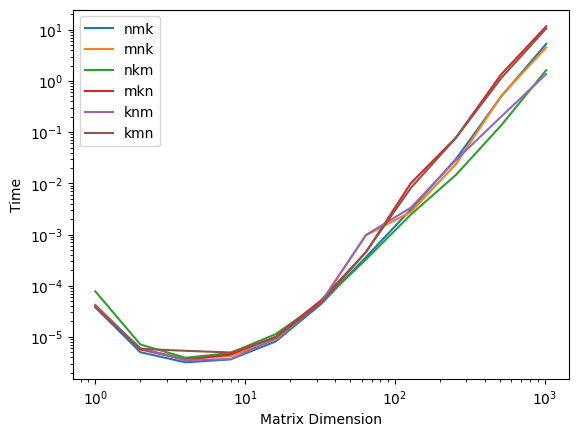

In [ ]:
Order = ['nmk', 'mnk', 'nkm', 'mkn', 'knm', 'kmn']

for ord in Order:
    #params, errors = curve_fit(CubeFunc, N, Time[order])
    #a, b, c, d = params

    plt.loglog(N, Result[ord], label = ord)
    plt.ylabel('Time')
    plt.xlabel('Matrix Dimension')
    plt.legend()
plt.show()

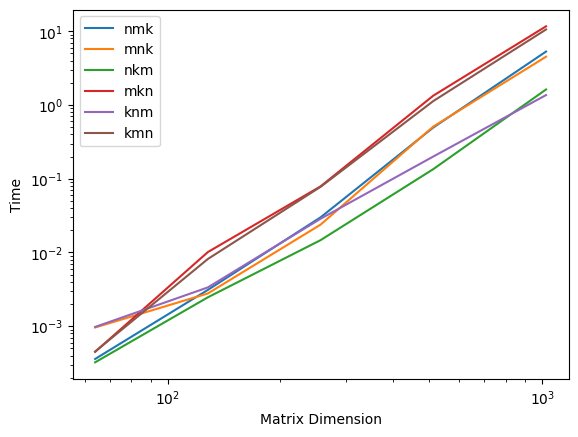

In [ ]:
for ord in Order:
    #params, errors = curve_fit(CubeFunc, N, Time[order])
    #a, b, c, d = params

    plt.loglog(N[6:], Result[ord][6:], label = ord)
    plt.ylabel('Time')
    plt.xlabel('Matrix Dimension')
    plt.legend()
plt.show()

Из графика видно, хуже всего работает алгоритм произведения матриц в порядке kmn и mkn, затем идут алгоритмы mnk nmk, а затем уже алгоритмы nkm и kmn. Алгоритм kmn работает хуже всего, так как сначала мы проходим цикл по столбцам первой матрицы, затем по строкам второй и затем уже по столбцам первой - в этом случае кэш используется неоптимально, как и в случае с mkn. Наилучшим образом работают алгоритмы, использующие индексирование по столбцам в последнюю очередь (kmn и nkm??)


### Задание 5

In [ ]:
#Алгоритм без ускорения

@nb.njit(nb.float64[:,:](nb.float64[:,:],nb.float64[:,:]))
def nb_my_dot(A,B):
    C=np.empty((A.shape[0],B.shape[1]))
    for n in range(A.shape[0]):
        for m in range(B.shape[1]):
            C[n, m] = np.sum( A[n,:]*B[:,m])
    return C

#Алгоритм с ускорением

@nb.njit(nb.float64[:,:](nb.float64[:,:],nb.float64[:,:]), parallel=True)
def nb_my_dot_multi(A,B):
    C=np.empty((A.shape[0],B.shape[1]))
    for n in nb.prange(A.shape[0]):
        for m in range(B.shape[1]):
            C[n, m] = np.sum( A[n,:]*B[:,m])
    return C

NN=np.logspace(1,3,100)
N=[int(i) for i in NN]
no_multitasking=measure_time(N, nb_my_dot, repeat=3)
yes_multitasking=measure_time(N, nb_my_dot_multi, repeat=3)


100%|██████████| 100/100 [01:07<00:00,  1.48it/s]


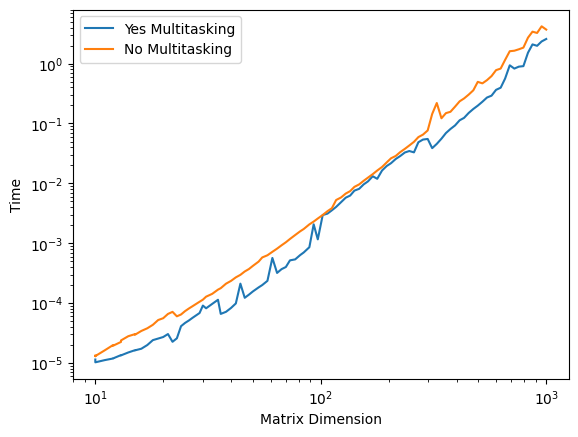

In [ ]:
plt.loglog(N, yes_multitasking, label = 'Yes Multitasking')
plt.loglog(N, no_multitasking, label = 'No Multitasking')
plt.ylabel('Time')
plt.xlabel('Matrix Dimension')
plt.legend()
plt.show()

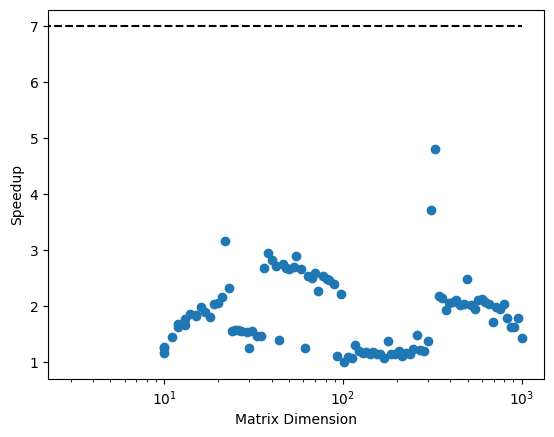

Максимльно полученное ускорение: 4.8142859070778075
0.39821426161527407
Ядра: 2 Потоки: 2


In [ ]:
p = np.array(no_multitasking)/np.array(yes_multitasking)

plt.xscale('log')
plt.scatter(N, p)
plt.hlines(7,0, 1000, linestyle = '--', color = 'black')
plt.ylabel('Speedup')
plt.xlabel('Matrix Dimension')

plt.show()

print('Максимльно полученное ускорение:',max(p))
print(1-max(p)/8)
import multiprocessing
print('Ядра:', multiprocessing.cpu_count(), 'Потоки:', nb.get_num_threads())


Из графика видно, что наибольшее получаемое ускорение стремится к 7 - на M1 с 8 ядрами (на Ryzen 3700x с 16 ядрами- ускорение порядка 20). Начальная задержка при параллельном вычислении связана с инициализацией параллельных процессов и составляет порядка $10^{-4}$


Задание 7. Реализуйте быстрое произведение матриц, например, используйте [алгоритм Штрассена](https://en.wikipedia.org/wiki/Strassen_algorithm).
Оцените, на матрицах какого размера быстрое произведение матриц быстрее, чем стандартная реализация.
Какой из методов дает меньшую погрешность вычислений?


In [ ]:
### Задание 7

In [ ]:
### Попробуем реализовать алгоритм Штрассена

# def make_matrix_even(A):
#     if A.shape[0] %2 !=0:
#         A=np.append(A, np.zeros((1,A.shape[1]), dtype=float),axis=0)
#     if A.shape[1] %2 !=0:
#         A=np.append(A, np.zeros((A.shape[0],1), dtype=float),axis=1)
#     return A

def split_matrix(A):
    A11=A[:A.shape[0]//2,:A.shape[1]//2]
    A12=A[:A.shape[0]//2,A.shape[1]//2:]
    A21=A[A.shape[0]//2:,:A.shape[1]//2]
    A22=A[A.shape[0]//2:,A.shape[1]//2:]
    return A11,A12,A21,A22


def strassen_dot(A,B):
    if A.shape[0] <= 16:
        return np.dot(A, B)
    #A,B=make_matrix_even(A),make_matrix_even(B)
    A11,A12,A21,A22=split_matrix(A)
    B11,B12,B21,B22=split_matrix(B)
    M1=strassen_dot(A11+A22,B11+B22)
    M2=strassen_dot(A21+A22,B11)
    M3=strassen_dot(A11, B12-B22)
    M4=strassen_dot(A22, B21-B11)
    M5=strassen_dot(A11+A12, B22)
    M6=strassen_dot(A21-A11,B11+B12)
    M7=strassen_dot(A12-A22,B21+B22)
    C11=M1+M4-M5+M7
    C12=M3+M5
    C21=M2+M4
    C22=M1-M2+M3+M6
    C=np.concatenate((np.concatenate((C11,C12),axis=1),np.concatenate((C21,C22),axis=1)), axis=0)
    return C

N=[2**n for n in range(2,11)]
shtassen=measure_time(N, strassen_dot, repeat=3)
my_dot_np=measure_time(N, np_my_dot, repeat=3)
my_dot_nb=measure_time(N, nb_my_dot, repeat=3)
my_dot_nb_multi=measure_time(N, nb_my_dot_multi, repeat=3)


100%|██████████| 9/9 [00:25<00:00,  2.86s/it]


In [ ]:
A=np.random.rand(32,32)
B=np.random.rand(32,32)

C=np.dot(A,B)- strassen_dot(A,B)

print(max(np.max(C, axis=0)))

8.881784197001252e-15


Проверил - моя реализация алгоритма Штрассена правильно умножает матрицы)


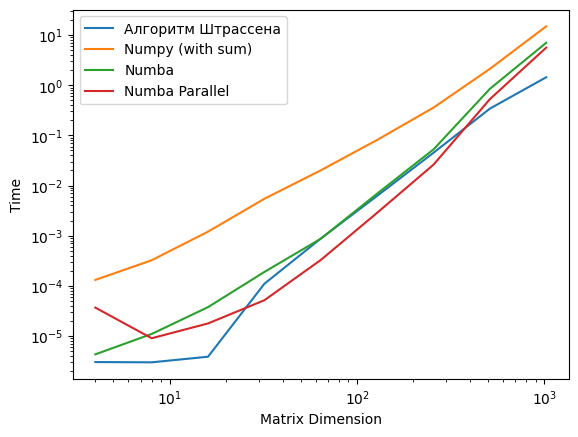

In [ ]:
plt.loglog(N, shtassen, label = 'Алгоритм Штрассена')
plt.loglog(N, my_dot_np, label = 'Numpy (with sum)')
plt.loglog(N, my_dot_nb, label = 'Numba')
plt.loglog(N, my_dot_nb_multi, label = 'Numba Parallel')
plt.ylabel('Time')
plt.xlabel('Matrix Dimension')
plt.legend()
plt.show()

Как кажется, алгоритм Штрассена работает на порядок лучше, чем страндратная реализация с функцией sum из Numpy, чуть лучше чем реализация с оптимизацией Numba, но не лучше чем метод, использующий параллельные вычисления.
